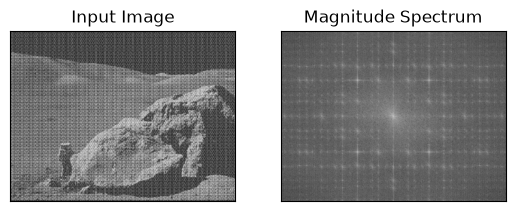

In [1]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
 
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

dft = cv.dft(np.float32(img),flags = cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
 
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
 
plt.subplot(121),plt.imshow(img, cmap = 'gray')
plt.title('Input Image'), plt.xticks([]), plt.yticks([])
plt.subplot(122),plt.imshow(magnitude_spectrum, cmap = 'gray')
plt.title('Magnitude Spectrum'), plt.xticks([]), plt.yticks([])
plt.show()

In [2]:
mask = np.zeros((img.shape[0],img.shape[1],2),np.uint8)
centerX, centerY = (int(img.shape[0] / 2),int(img.shape[1] / 2))
mask[centerX-50:centerX+50, centerY - 50:centerY+50,:] = 1

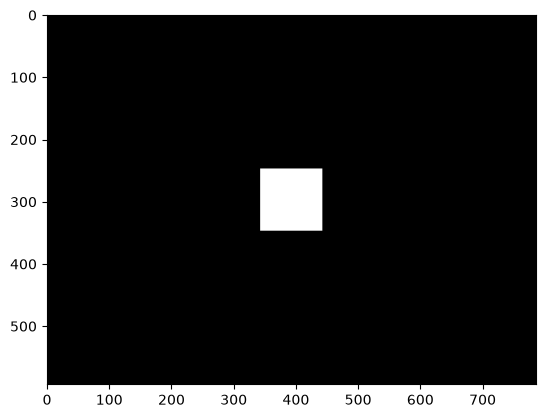

In [3]:
plt.imshow(mask[:,:,0], cmap = 'gray')

In [4]:
dft_shift = dft_shift*mask

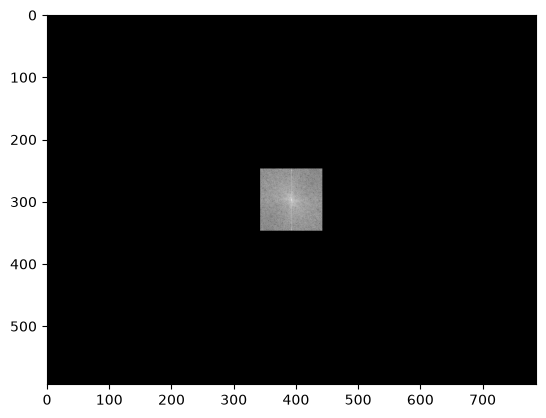

In [5]:
filtering_magn_res = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1)
plt.imshow(filtering_magn_res, cmap='gray')

In [6]:
f_ishift = np.fft.ifftshift(dft_shift)
img_back = cv.idft(f_ishift, flags=cv.DFT_SCALE | cv.DFT_REAL_OUTPUT)

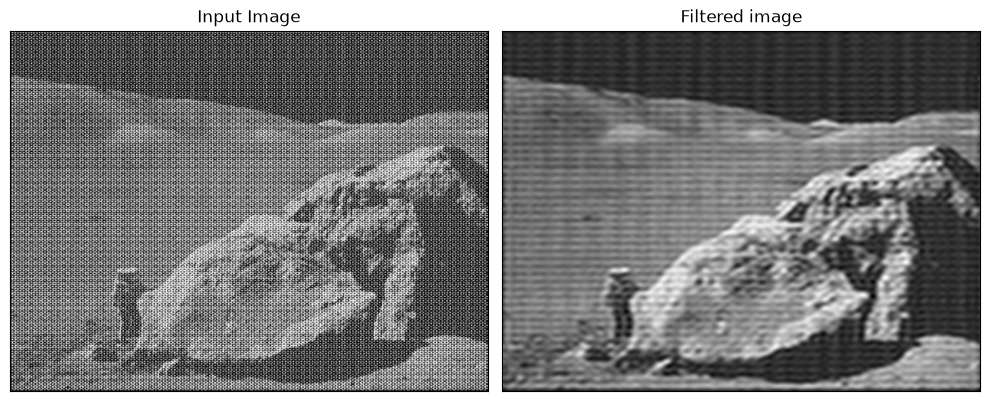

In [7]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Input Image')
plt.xticks([]), plt.yticks([])
plt.subplot(1, 2, 2)
plt.imshow(img_back, cmap='gray')
plt.title('Filtered image')
plt.xticks([]), plt.yticks([])
plt.tight_layout()
plt.show()

# Task 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

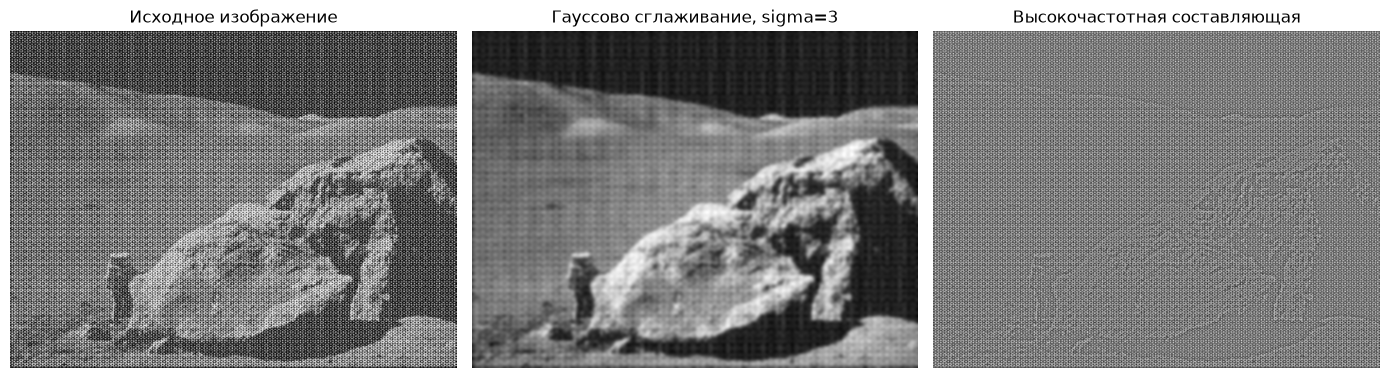

In [8]:
sigma = 3
img_float = img.astype(np.float32)
gaussian_blur = cv.GaussianBlur(img_float, (0, 0), sigmaX=sigma, sigmaY=sigma)

high_pass = img_float - gaussian_blur
high_pass_view = cv.normalize(high_pass, None, 0, 255, cv.NORM_MINMAX).astype(np.uint8)

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(gaussian_blur, cmap='gray')
plt.title(f'Гауссово сглаживание, sigma={sigma}')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(high_pass_view, cmap='gray')
plt.title('Высокочастотная составляющая')
plt.axis('off')
plt.tight_layout()
plt.show()

# Task 2. Реализуйте вычисление свертки с помощью преобразования Фурье

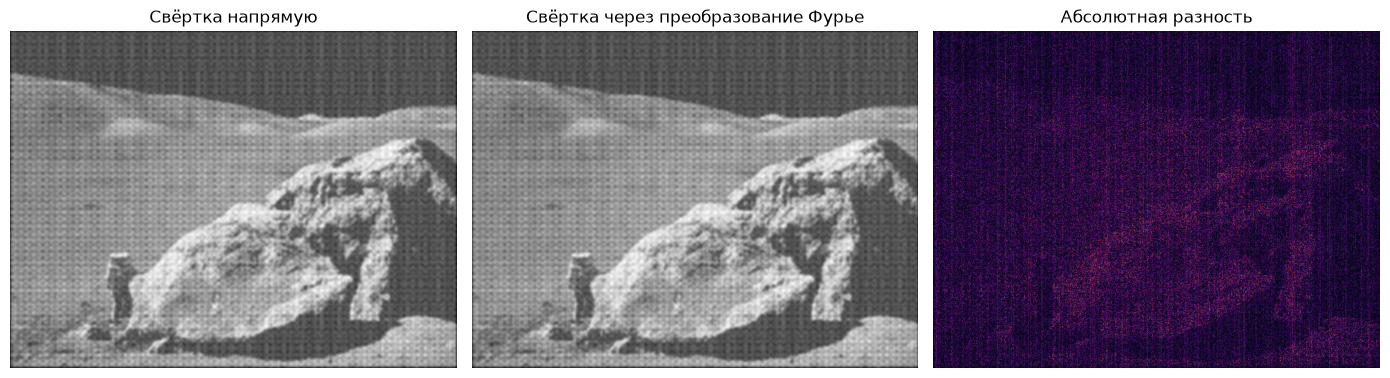

Максимальное абсолютное различие: 0.000137


In [9]:
kernel_size = 9
sigma_kernel = 2
one_d = cv.getGaussianKernel(kernel_size, sigma_kernel)
gaussian_kernel = one_d @ one_d.T

image_float = img.astype(np.float32)
conv_direct = cv.filter2D(image_float, ddepth=-1, kernel=gaussian_kernel,
                          borderType=cv.BORDER_CONSTANT)

h, w = image_float.shape
kh, kw = gaussian_kernel.shape
fft_shape = (h + kh - 1, w + kw - 1)
image_padded = np.zeros(fft_shape, dtype=np.float32)
kernel_padded = np.zeros(fft_shape, dtype=np.float32)
image_padded[:h, :w] = image_float
kernel_padded[:kh, :kw] = gaussian_kernel

F_image = np.fft.fft2(image_padded)
F_kernel = np.fft.fft2(kernel_padded)
conv_full = np.fft.ifft2(F_image * F_kernel).real
conv_fft = conv_full[kh//2:kh//2+h, kw//2:kw//2+w]

max_difference = float(np.max(np.abs(conv_direct - conv_fft)))

plt.figure(figsize=(14, 4))
plt.subplot(1, 3, 1)
plt.imshow(conv_direct, cmap='gray')
plt.title('Свёртка напрямую')
plt.axis('off')
plt.subplot(1, 3, 2)
plt.imshow(conv_fft, cmap='gray')
plt.title('Свёртка через преобразование Фурье')
plt.axis('off')
plt.subplot(1, 3, 3)
plt.imshow(np.abs(conv_direct - conv_fft), cmap='inferno')
plt.title('Абсолютная разность')
plt.axis('off')
plt.tight_layout()
plt.show()

print(f'Максимальное абсолютное различие: {max_difference:.6f}')

# Task 3. Реализуйте удаление периодического шума с помощью преобразования Фурье

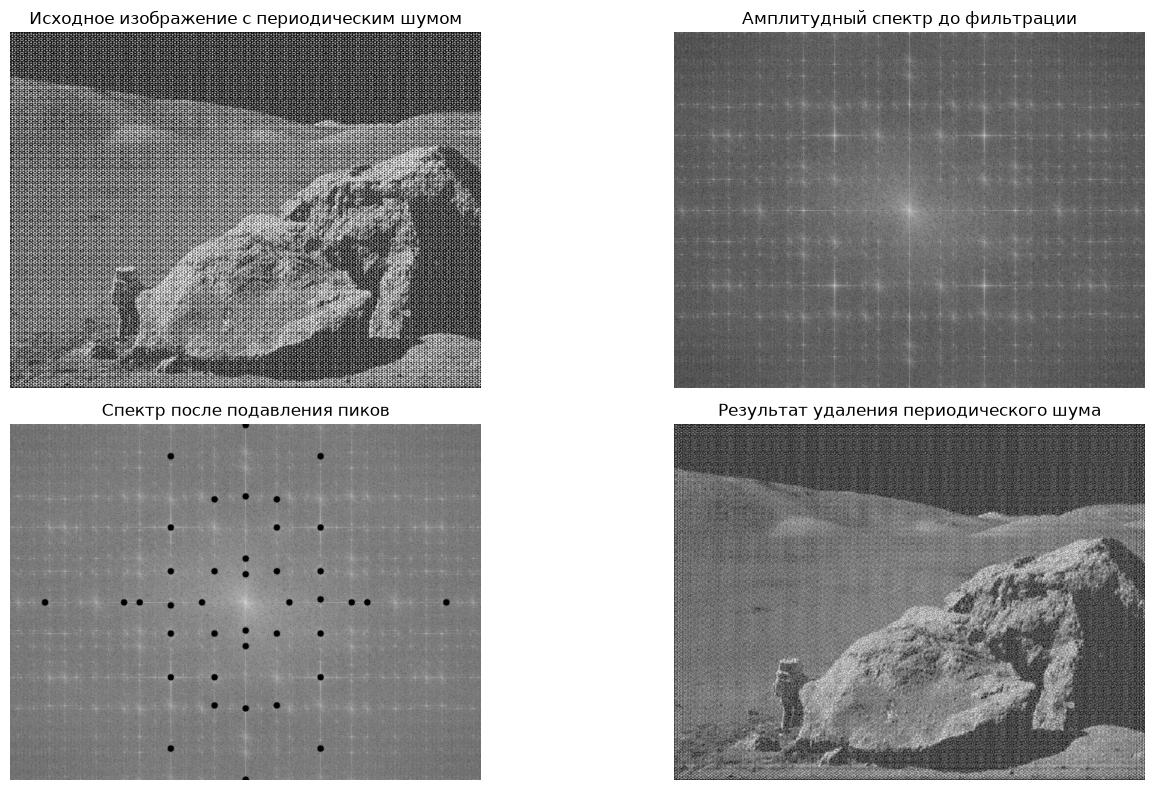

Количество выбранных спектральных пиков: 20 (максимум 20)
Среднеквадратичное изменение изображения: 63.453


In [10]:
image_float = img.astype(np.float32)
F = np.fft.fft2(image_float)
F_shift = np.fft.fftshift(F)
rows, cols = img.shape
cy, cx = rows // 2, cols // 2
spectrum_before = 20 * np.log1p(np.abs(F_shift))

Y, X = np.ogrid[:rows, :cols]
distance_from_center = np.sqrt((Y - cy)**2 + (X - cx)**2)
spectrum_for_peaks = spectrum_before.copy()
spectrum_for_peaks[distance_from_center < 25] = -1
valid_spectrum = spectrum_for_peaks[spectrum_for_peaks >= 0]
if valid_spectrum.size == 0:
    raise ValueError('Не удалось найти область спектра для поиска периодического шума.')

peak_threshold = np.percentile(valid_spectrum, 99.8)
local_maximum = cv.dilate(spectrum_for_peaks.astype(np.float32), np.ones((5, 5), np.uint8))
candidates = np.argwhere((spectrum_for_peaks == local_maximum) & (spectrum_for_peaks > peak_threshold))
candidates = sorted(candidates, key=lambda point: spectrum_for_peaks[point[0], point[1]], reverse=True)

max_peaks = 20
min_separation = 12
peak_points = []
for py, px in candidates:
    py, px = int(py), int(px)
    if py < cy or (py == cy and px < cx):
        continue
    mirror_y = (2 * cy - py) % rows
    mirror_x = (2 * cx - px) % cols
    too_close = False
    for qy, qx in peak_points:
        qmirror_y = (2 * cy - qy) % rows
        qmirror_x = (2 * cx - qx) % cols
        distances = [
            np.hypot(py - qy, px - qx),
            np.hypot(py - qmirror_y, px - qmirror_x),
            np.hypot(mirror_y - qy, mirror_x - qx),
            np.hypot(mirror_y - qmirror_y, mirror_x - qmirror_x),
        ]
        if min(distances) < min_separation:
            too_close = True
            break
    if not too_close:
        peak_points.append((py, px))
    if len(peak_points) >= max_peaks:
        break

notch_mask = np.ones((rows, cols), dtype=np.float32)
notch_radius = 5
transition_radius = 8
for py, px in peak_points:
    mirror_y = (2 * cy - py) % rows
    mirror_x = (2 * cx - px) % cols
    for fy, fx in {(py, px), (mirror_y, mirror_x)}:
        distance = np.sqrt((Y - fy)**2 + (X - fx)**2)
        local_mask = np.ones((rows, cols), dtype=np.float32)
        inside = distance <= notch_radius
        transition = (distance > notch_radius) & (distance < transition_radius)
        local_mask[inside] = 0.0
        local_mask[transition] = 0.5 * (
            1 - np.cos(np.pi * (distance[transition] - notch_radius) /
                       (transition_radius - notch_radius))
        )
        notch_mask *= local_mask

F_filtered_shift = F_shift * notch_mask
spectrum_after = 20 * np.log1p(np.abs(F_filtered_shift))
F_filtered = np.fft.ifftshift(F_filtered_shift)
img_denoised_float = np.fft.ifft2(F_filtered).real
img_denoised = np.clip(img_denoised_float, 0, 255).astype(np.uint8)

rms_change = float(np.sqrt(np.mean((img.astype(np.float32) - img_denoised.astype(np.float32))**2)))

plt.figure(figsize=(15, 8))
plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение с периодическим шумом')
plt.axis('off')
plt.subplot(2, 2, 2)
plt.imshow(spectrum_before, cmap='gray')
plt.title('Амплитудный спектр до фильтрации')
plt.axis('off')
plt.subplot(2, 2, 3)

spectrum_after_display = cv.normalize(
    spectrum_after, None, 0, 255, cv.NORM_MINMAX
).astype(np.uint8)

for py, px in peak_points:
    mirror_y = (2 * cy - py) % rows
    mirror_x = (2 * cx - px) % cols
    cv.circle(spectrum_after_display, (px, py), 3, 0, -1)
    cv.circle(spectrum_after_display, (mirror_x, mirror_y), 3, 0, -1)
plt.imshow(spectrum_after_display, cmap='gray', vmin=0, vmax=255)
plt.title('Спектр после подавления пиков')
plt.axis('off')
plt.subplot(2, 2, 4)
plt.imshow(img_denoised, cmap='gray')
plt.title('Результат удаления периодического шума')
plt.axis('off')
plt.tight_layout()
plt.show()

print(f'Количество выбранных спектральных пиков: {len(peak_points)} (максимум {max_peaks})')
print(f'Среднеквадратичное изменение изображения: {rms_change:.3f}')